# 1C-9. 테스트 구간 평가 — 한 번만

**사람의 승인(2026-10-07)을 받아 실행한다.** 모형 선택은 `output/models/selection.csv`에 고정돼 있고(커밋 `b8f2f00`), 여기서는 그 선택대로 예측해 채점만 한다.
**결과를 보고 모형을 바꾸지 않는다.** 바꾸는 순간 테스트 구간도 "보고 고른 자료"가 되어 최종 성능이라고 말할 수 없게 된다.

**하는 일**
1. 선택 모형과 함께 보고할 모형을 **학습 + 검증 구간(~ 2024-12-25 원점, 일 단위 모형은 ~ 2024-12-31)**으로 다시 맞춘다. 설정(변수, 멈춤 시점 정하는 방법)은 검증에서 정한 그대로.
2. 테스트 원점(2025-01-01 ~ 2026-06-24)을 예측하고 채점한다.
3. 반기별(2025 상반기·하반기·2026 상반기) 성능과 편향, 월요일 원점만, 보정한 80% 구간의 적중률, 선택 모형 대 나이브의 통계 검정.
4. 날씨 시나리오 A·B·C·D별 성능(날씨 정보의 가치).

| 구분 | 모형 | 역할 |
|---|---|---|
| **주 모형** | 선택한 음이항(타이어·체인·안장·전체 GLM_B, 페달 GLMk_B) | 최종 성능은 이것으로 말한다 |
| 함께 보고 | 나이브 B1, 구조 나이브 S1, GRU | 결정(2026-10-05): 나란히 적는다 |
| 조건 비교 | 음이항의 날씨 A·B·C·D | 예보 오차의 비용, 날씨 정보의 가치 |

**테스트 구간은 다른 레짐이다**(2025-03부터 신고율 약 20% 하락, 체크포인트 A). 검증보다 나빠도 그대로 적는다.

In [1]:
%load_ext autoreload
%autoreload 2
import sys; sys.path.append("../py")
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
from scipy import stats
plt.rcParams["font.family"] = "AppleGothic"; plt.rcParams["axes.unicode_minus"] = False
pd.set_option("display.width", 240); pd.set_option("display.max_columns", 40); pd.set_option("display.max_rows", 100)
ROOT = Path("..")
from fc import *
from fc_models import *
from fc_expo import expo_rows, lgb_rounds, fit_expo_lgb, E2_WX
from fc_dl import make_arrays, fit_predict_gru

sel = pd.read_csv(ROOT / "output/models/selection.csv")             # 고정한 선택
cal = pd.read_csv(ROOT / "output/models/interval_calibration.csv")  # 검증 구간에서 구한 구간 보정값
print(sel[["부품", "선택", "검증 skill", "r_lo", "r_hi", "확정일"]].to_string(index=False))

m = load_master()
base = make_base(m, include_test=True)                               # 테스트 원점을 만든다(승인 뒤)
END_DAY = "2024-12-31"                                                # 일 단위 모형의 학습 마지막 날(학습 + 검증)
tv = base[base.split.isin(["train", "valid"]) & base.clean & (base.part == "total_faults") & (base.origin >= "2021-05-06")].i.to_numpy()   # 학습 + 검증 원점
te = base[(base.split == "test") & (base.part == "total_faults")].i.to_numpy()                                                              # 테스트 원점
HOLD_FROM = int(np.where(m.date >= "2024-03-01")[0][0])              # GRU의 멈춤 시점 정하기용 뒤쪽 원점(검증 구간을 다시 학습에 쓰므로 그 뒤쪽)
print("다시 학습하는 원점", len(tv), "개 (~", m.date[tv[-1]].date(), ") / 테스트 원점", len(te), "개 (", m.date[te[0]].date(), "~", m.date[te[-1]].date(), ")")

preds = []
def add(df, part, model):
    out = df.assign(origin=m.date.to_numpy()[df.oi.to_numpy()], part=part, model=model)
    preds.append(out[[c for c in ["origin", "part", "model", "pred", "q10", "q90"] if c in out]])
def save_tab(x, name, index=True):
    x.to_csv(ROOT / f"output/tables/fc_{name}.csv", index=index); return x

 부품     선택  검증 skill      r_lo     r_hi        확정일
타이어  GLM_B     0.408 -0.222287 0.096781 2026-10-07
 체인  GLM_B     0.316 -0.179914 0.324260 2026-10-07
 안장  GLM_B     0.384 -0.264569 0.182876 2026-10-07
 페달 GLMk_B     0.344 -0.158593 0.273765 2026-10-07
 전체  GLM_B     0.361 -0.221163 0.156004 2026-10-07
다시 학습하는 원점 1221 개 (~ 2024-12-25 ) / 테스트 원점 540 개 ( 2025-01-01 ~ 2026-06-24 )


## 1. 다시 학습 — 학습 + 검증 구간으로

대여량 모형(K2)과 신고율 모형(GLM, GLMk, GRU)을 2024년까지 넣어 다시 맞춘다. 검증에서 정한 설정은 그대로다.

In [2]:
# 대여량 모형
expo_A = fit_expo(m, end=END_DAY)                                              # A: 실측으로 학습한 음이항
expo_D = fit_expo(m, weather=False, end=END_DAY)                               # D: 날씨 없음
rows_B = expo_rows(m, TRAIN_DAYS[0], END_DAY, "B")
expo_B = fit_nb_fc("rentals ~ " + EXPO_CAL + E2_WX, rows_B.assign(tavg_anom=rows_B.tavg - rows_B.tavg_normal))[0]   # B: K2
rows_C = expo_rows(m, TRAIN_DAYS[0], END_DAY, "C"); expo_C = fit_expo_lgb(rows_C, lgb_rounds(rows_C))              # C: N5(비교)
k2 = lambda f: np.asarray(expo_B.predict(f.assign(tavg_anom=f.tavg - f.tavg_normal)))

F, E = {}, {}
for scn in "ABC":
    F[scn] = future_frame(m, te, scn)
E["A"] = np.asarray(expo_A.predict(F["A"])); E["B"] = k2(F["B"]); E["C"] = np.asarray(expo_C(F["C"]))
F["D"] = F["A"]; E["D"] = np.asarray(expo_D.predict(F["D"]))

act = F["A"].groupby("oi").rentals.sum()
wk = lambda hat, scn: pd.Series(np.asarray(hat)).groupby(F[scn].oi.to_numpy()).sum().to_numpy()
rows = [{"방법": "지난주 대여량 그대로", "hat": sum_back(m.rentals, 7).iloc[te].to_numpy()}] + \
       [{"방법": f"{scn}: {nm}", "hat": wk(E[scn], scn)} for scn, nm in (("A", "음이항, 날씨 실측(상한)"), ("B", "음이항 K2, 기상청 예보"), ("C", "LightGBM N5, 오차 가정"), ("D", "음이항, 날씨 없음"))]
save_tab(pd.DataFrame([{"방법": r["방법"], "MAE%": float(np.abs(r["hat"] - act.to_numpy()).mean() / act.mean() * 100),
                        "bias%": float((r["hat"] - act.to_numpy()).mean() / act.mean() * 100)} for r in rows]).set_index("방법").round(2), "expo_test")

/Users/junyeop/dareungi/.venv/lib/python3.14/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
/Users/junyeop/dareungi/.venv/lib/python3.14/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
/Users/junyeop/dareungi/.venv/lib/python3.14/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
/Users/junyeop/dareungi/.venv/lib/python3.14/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model pa

/Users/junyeop/dareungi/.venv/lib/python3.14/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
/Users/junyeop/dareungi/.venv/lib/python3.14/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
/Users/junyeop/dareungi/.venv/lib/python3.14/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
/Users/junyeop/dareungi/.venv/lib/python3.14/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model pa

,MAE%,bias%
방법,,
지난주 대여량 그대로,14.33,-0.91
"A: 음이항, 날씨 실측(상한)",7.48,2.64
"B: 음이항 K2, 기상청 예보",10.25,6.53
"C: LightGBM N5, 오차 가정",9.17,2.99
"D: 음이항, 날씨 없음",11.82,3.70


In [3]:
# 신고율 모형: 음이항(실측으로 학습), 음이항(예보로 학습), 구조 나이브
F_tvB = future_frame(m, tv, "B")
for part in PARTS:
    add(predict_s1(F["B"], part, E["B"]), part, "S1_B")
    fit = fit_glm(m, part, end=END_DAY)
    for scn in "ABC":
        add(predict_glm(fit, F[scn], part, E[scn]), part, f"GLM_{scn}")
    add(predict_glm(fit_glm(m, part, weather=False, end=END_DAY), F["D"], part, E["D"]), part, "GLM_D")
    add(predict_glm(fit_glm_rows(F_tvB, part), F["B"], part, E["B"]), part, "GLMk_B")
print("음이항 완료")

음이항 완료


In [4]:
# GRU: 학습 + 검증 원점으로 다시 학습(날씨는 실측, 대여량은 K2 예측). 멈춤 시점은 2024-03-01 이후 원점으로 정한다
F_tv = future_frame(m, tv, "A"); E_tv = k2(F_tvB)
for part in PARTS:
    y_all = base[base.part == part].set_index("i").y
    add(fit_predict_gru(make_arrays(m, part, F_tv, E_tv), y_all.loc[tv].to_numpy(), tv >= HOLD_FROM, make_arrays(m, part, F["B"], E["B"])), part, "GRU_B")
print("GRU 완료")

GRU 완료


## 2. 테스트 채점

주 모형은 부품별 선택(`selected`)이다. 함께 보고: B1, S1, GLM(두 판), GRU. 조건 비교: GLM의 A·C·D.

In [5]:
naive = base[base.split == "test"].melt(id_vars=["origin", "part"], value_vars=["B1", "B2", "B3", "B4"], var_name="model", value_name="pred").dropna()
test_preds = pd.concat(preds + [naive], ignore_index=True)
pick = dict(zip(sel.part, sel["선택"]))
chosen = pd.concat([test_preds[(test_preds.part == p) & (test_preds.model == mdl)].assign(model="selected") for p, mdl in pick.items()])
test_preds = pd.concat([test_preds, chosen], ignore_index=True)
test_preds.to_parquet(ROOT / "output/models/test_predictions.parquet", index=False)

sc = score(test_preds, base); sc = sc[sc.split == "test"].drop(columns="split")
save_tab(sc.round(4), "test", index=False)
ORDER = ["B1", "B2", "B3", "B4", "S1_B", "GLM_B", "GLMk_B", "selected", "GRU_B", "GLM_A", "GLM_C", "GLM_D"]
skill = sc.pivot(index="model", columns="part", values="skill").rename(columns=PARTS).reindex(ORDER)[list(PARTS.values())]
print("채점한 원점 수:", int(sc.n.iloc[0]))
print("skill (나이브 B1 대비 오차 감소 비율)"); display(skill.round(3))
print("MAE% (오차 ÷ 실제 평균)"); display(sc.pivot(index="model", columns="part", values="MAEpct").rename(columns=PARTS).reindex(ORDER)[list(PARTS.values())].round(1))
ymean = base[base.split == "test"].groupby("part").y.mean()
print("bias ÷ 실제 평균 (%): 양수 = 과대예측"); display((100 * sc.pivot(index="model", columns="part", values="bias") / ymean).rename(columns=PARTS).reindex(ORDER)[list(PARTS.values())].round(1))

채점한 원점 수: 540
skill (나이브 B1 대비 오차 감소 비율)


part,타이어,체인,안장,페달,전체
model,,,,,
B1,0.000,0.000,0.000,0.000,0.000
B2,-0.056,0.022,0.005,0.007,0.003
B3,-0.832,-2.561,-1.157,-1.683,-1.248
B4,-0.119,-0.314,-0.153,-0.119,-0.181
S1_B,0.257,0.150,0.238,0.266,0.224
GLM_B,0.028,-0.172,0.276,-0.089,-0.024
GLMk_B,0.038,-0.261,0.253,-0.194,-0.048
selected,0.028,-0.172,0.276,-0.194,-0.024
GRU_B,0.079,0.189,0.330,0.019,0.061


MAE% (오차 ÷ 실제 평균)


part,타이어,체인,안장,페달,전체
model,,,,,
B1,16.4,18.1,18.8,19.0,16.3
B2,17.4,17.7,18.7,18.9,16.3
B3,30.1,64.3,40.6,51.0,36.7
B4,18.4,23.7,21.7,21.3,19.3
S1_B,12.2,15.4,14.3,13.9,12.6
GLM_B,16.0,21.2,13.6,20.7,16.7
GLMk_B,15.8,22.8,14.1,22.7,17.1
selected,16.0,21.2,13.6,22.7,16.7
GRU_B,15.1,14.6,12.6,18.6,15.3


bias ÷ 실제 평균 (%): 양수 = 과대예측


part,타이어,체인,안장,페달,전체
model,,,,,
B1,-1.0,-0.6,-0.5,-0.7,-0.7
B2,-2.2,-1.4,-1.4,-1.3,-1.7
B3,24.2,56.2,34.1,48.4,31.0
B4,0.8,1.2,-0.3,2.3,0.3
S1_B,5.6,7.2,7.2,7.1,6.8
GLM_B,12.8,18.5,6.6,17.9,15.0
GLMk_B,12.7,20.4,7.6,20.4,15.6
selected,12.8,18.5,6.6,20.4,15.0
GRU_B,10.6,7.8,1.5,14.0,11.9


### 검증 대 테스트 — 낙관 편향의 크기

검증 구간은 모형을 고를 때 본 자료라 점수가 실제보다 좋게 나온다. 테스트와의 차이가 그 크기다(1차 분석이 테스트로 설정을 골랐을 때 얼마나 부풀었을지 가늠하는 근거).

In [6]:
va = pd.read_csv(ROOT / "output/tables/fc_valid.csv")
va_sk = va.pivot(index="model", columns="part", values="skill").rename(columns=PARTS)
cmp = pd.DataFrame({"검증 skill(선택 모형)": [va_sk.loc[pick[p], PARTS[p]] for p in PARTS], "테스트 skill(선택 모형)": skill.loc["selected"].to_numpy()}, index=list(PARTS.values()))
cmp["차이(검증 − 테스트)"] = cmp.iloc[:, 0] - cmp.iloc[:, 1]
save_tab(cmp.round(3), "test_vs_valid")

,검증 skill(선택 모형),테스트 skill(선택 모형),차이(검증 − 테스트)
타이어,0.408,0.028,0.380
체인,0.316,-0.172,0.488
안장,0.384,0.276,0.108
페달,0.344,-0.194,0.538
전체,0.361,-0.024,0.385


## 3. 반기별 — 레짐 변화가 드러나는가

2025-03부터 신고율이 약 20% 낮아졌다. 모형이 최근 4주 신고율로 수준을 따라가므로 편향이 작아야 하지만, 바뀌는 시점(2025 상반기)에서는 과대예측이 나올 수 있다.

In [7]:
tp = test_preds.merge(base[["origin", "part", "y", "B1"]], on=["origin", "part"])
tp["반기"] = np.select([tp.origin < "2025-07-01", tp.origin < "2026-01-01"], ["2025 상반기", "2025 하반기"], "2026 상반기")
rows = []
for (half, part, mdl), g in tp[tp.model.isin(["B1", "S1_B", "selected", "GRU_B"])].groupby(["반기", "part", "model"]):
    rows.append({"반기": half, "부품": PARTS[part], "모형": mdl, "n": len(g), "MAE%": 100 * (g.pred - g.y).abs().mean() / g.y.mean(),
                 "skill": 1 - (g.pred - g.y).abs().mean() / (g.B1 - g.y).abs().mean(), "bias%": 100 * (g.pred - g.y).mean() / g.y.mean()})
half = pd.DataFrame(rows)
save_tab(half.round(3), "test_half", index=False)
print("skill (반기 × 모형)"); display(half.pivot_table(index=["반기", "모형"], columns="부품", values="skill")[list(PARTS.values())].round(3))
print("bias% (양수 = 과대예측)"); display(half[half.model == "selected" if "model" in half else half.모형 == "selected"].pivot(index="반기", columns="부품", values="bias%")[list(PARTS.values())].round(1))

skill (반기 × 모형)


부품                   타이어     체인     안장     페달     전체
반기       모형                                         
2025 상반기 B1        0.000  0.000  0.000  0.000  0.000
         GRU_B     0.088  0.345  0.465  0.210  0.158
         S1_B      0.277  0.174  0.359  0.390  0.263
         selected  0.025 -0.055  0.372  0.191  0.105
2025 하반기 B1        0.000  0.000  0.000  0.000  0.000
         GRU_B     0.095  0.189  0.252  0.078  0.218
         S1_B      0.171  0.217  0.173  0.220  0.245
         selected  0.037 -0.041  0.258 -0.171  0.023
2026 상반기 B1        0.000  0.000  0.000  0.000  0.000
         GRU_B     0.042 -0.005  0.261 -0.413 -0.269
         S1_B      0.387  0.027  0.169  0.171  0.151
         selected  0.016 -0.504  0.173 -0.857 -0.239

bias% (양수 = 과대예측)


부품,타이어,체인,안장,페달,전체
반기,,,,,
2025 상반기,11.8,16.6,6.1,10.7,12.8
2025 하반기,13.2,18.8,4.5,25.1,16.0
2026 상반기,13.3,20.1,9.6,26.2,16.3


## 4. 월요일 원점, 예측구간, 통계 검정

In [8]:
mon = test_preds[test_preds.origin.dt.dayofweek == 0]
sm_ = score(mon, base); sm_ = sm_[sm_.split == "test"]
print("월요일 원점 수:", int(sm_.n.iloc[0]), "| skill")
display(save_tab(sm_.pivot(index="model", columns="part", values="skill").rename(columns=PARTS).reindex(["B1", "S1_B", "selected", "GRU_B"])[list(PARTS.values())].round(3), "test_monday"))

# 보정한 80% 구간(검증 상대오차의 10~90% 범위)에 테스트 실제값이 든 비율. 목표 0.80
rows = []
for part, mdl in pick.items():
    c_ = cal[(cal.part == part) & (cal.model == mdl)].iloc[0]
    g = tp[(tp.part == part) & (tp.model == "selected")]
    inside = (g.y >= g.pred * (1 + c_.r_lo)) & (g.y <= g.pred * (1 + c_.r_hi))
    rows.append({"부품": PARTS[part], "모형": mdl, "r_lo": c_.r_lo, "r_hi": c_.r_hi, "구간 안에 든 비율": inside.mean(),
                 "아래로 벗어남": (g.y < g.pred * (1 + c_.r_lo)).mean(), "위로 벗어남": (g.y > g.pred * (1 + c_.r_hi)).mean()})
print("보정한 80% 구간의 적중률(테스트)"); display(save_tab(pd.DataFrame(rows).set_index("부품").round(3), "test_coverage"))

def dm_test(e1, e2, h=7):
    """Diebold-Mariano 검정: 두 모형의 오차(절댓값) 차이가 0이라고 할 수 있는가. 음수 통계량 = 모형 1이 더 정확. 7일 합계가 겹치므로 h = 7"""
    d = np.abs(np.asarray(e1)) - np.abs(np.asarray(e2)); n, dbar = len(d), d.mean()
    gam = [np.mean((d[k:] - dbar) * (d[:n - k] - dbar)) for k in range(h)]
    stat = dbar / np.sqrt((gam[0] + 2 * sum(gam[1:])) / n) * np.sqrt((n + 1 - 2 * h + h * (h - 1) / n) / n)
    return stat, 2 * stats.t.sf(abs(stat), df=n - 1)
rows = []
for part in PARTS:
    g = tp[(tp.part == part) & (tp.model == "selected")].sort_values("origin")
    st, p_ = dm_test(g.pred - g.y, g.B1 - g.y)
    rows.append({"부품": PARTS[part], "DM 통계량": st, "p값": p_, "해석": "선택 모형이 나이브보다 유의하게 정확" if (st < 0 and p_ < 0.05) else "차이가 유의하지 않음"})
print("선택 모형 vs 나이브 B1 (Diebold-Mariano 검정)"); display(save_tab(pd.DataFrame(rows).set_index("부품").round(4), "test_dm"))

월요일 원점 수: 77 | skill


part,타이어,체인,안장,페달,전체
model,,,,,
B1,0.000,0.000,0.000,0.000,0.000
S1_B,0.287,0.149,0.233,0.311,0.223
selected,0.018,-0.164,0.251,-0.170,-0.026
GRU_B,0.117,0.138,0.336,0.047,0.021


보정한 80% 구간의 적중률(테스트)


,모형,r_lo,r_hi,구간 안에 든 비율,아래로 벗어남,위로 벗어남
부품,,,,,,
타이어,GLM_B,-0.222,0.097,0.770,0.141,0.089
체인,GLM_B,-0.180,0.324,0.587,0.398,0.015
안장,GLM_B,-0.265,0.183,0.846,0.072,0.081
페달,GLMk_B,-0.159,0.274,0.515,0.478,0.007
전체,GLM_B,-0.221,0.156,0.793,0.189,0.019


선택 모형 vs 나이브 B1 (Diebold-Mariano 검정)


,DM 통계량,p값,해석
부품,,,
타이어,-0.2669,0.7897,차이가 유의하지 않음
체인,1.6996,0.0898,차이가 유의하지 않음
안장,-3.9670,0.0001,선택 모형이 나이브보다 유의하게 정확
페달,1.6190,0.1060,차이가 유의하지 않음
전체,0.2475,0.8046,차이가 유의하지 않음


## 5. 날씨 정보의 가치 (테스트, 음이항 기준)

A(완벽한 예보) − B(기상청 예보) = 예보 오차의 비용, B − D(날씨 없음) = 날씨 정보의 가치. C = 처음에 가정했던 예보 오차.

In [9]:
save_tab(pd.DataFrame({"A 실측(상한)": skill.loc["GLM_A"], "B 기상청 예보": skill.loc["GLM_B"], "C 오차 가정": skill.loc["GLM_C"], "D 날씨 없음": skill.loc["GLM_D"]}).T.round(3), "scenarios_test")

part,타이어,체인,안장,페달,전체
A 실측(상한),0.243,0.020,0.424,0.039,0.189
B 기상청 예보,0.028,-0.172,0.276,-0.089,-0.024
C 오차 가정,0.172,0.029,0.353,0.039,0.142
D 날씨 없음,0.096,-0.086,0.180,-0.071,0.107


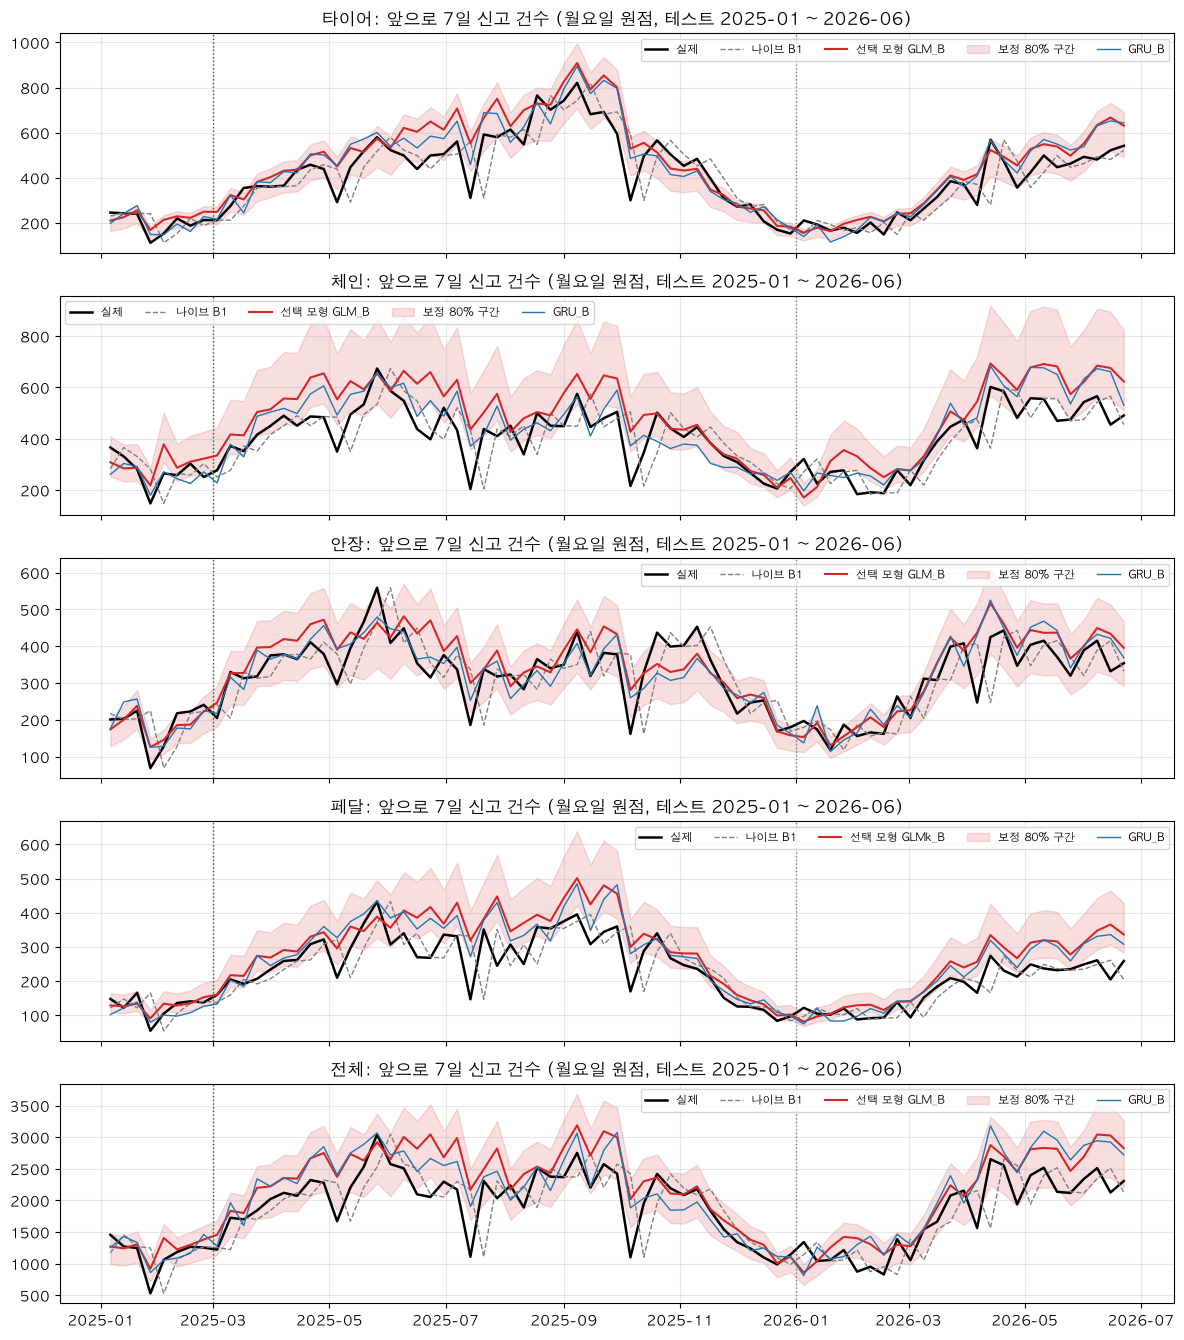

In [10]:
# 그림: 테스트 구간 주간 실제 vs 선택 모형 예측(월요일 원점), 보정 80% 구간 띠
fig, axes = plt.subplots(len(PARTS), 1, figsize=(12, 2.7 * len(PARTS)), sharex=True)
for ax, (part, name) in zip(axes, PARTS.items()):
    c_ = cal[(cal.part == part) & (cal.model == pick[part])].iloc[0]
    a = base[(base.part == part) & (base.split == "test") & (base.origin.dt.dayofweek == 0)].set_index("origin")
    p = test_preds[(test_preds.part == part) & (test_preds.model == "selected") & (test_preds.origin.dt.dayofweek == 0)].set_index("origin")
    g = test_preds[(test_preds.part == part) & (test_preds.model == "GRU_B") & (test_preds.origin.dt.dayofweek == 0)].set_index("origin")
    ax.plot(a.index, a.y, color="black", lw=1.8, label="실제"); ax.plot(a.index, a.B1, color="gray", lw=1, ls="--", label="나이브 B1")
    ax.plot(p.index, p.pred, color="tab:red", lw=1.5, label=f"선택 모형 {pick[part]}")
    ax.fill_between(p.index, p.pred * (1 + c_.r_lo), p.pred * (1 + c_.r_hi), color="tab:red", alpha=0.15, label="보정 80% 구간")
    ax.plot(g.index, g.pred, color="tab:blue", lw=1, label="GRU_B")
    ax.axvline(pd.Timestamp("2025-03-01"), color="green", ls=":", lw=1); ax.axvline(pd.Timestamp("2026-01-01"), color="gray", ls=":", lw=1)
    ax.set_title(f"{name}: 앞으로 7일 신고 건수 (월요일 원점, 테스트 2025-01 ~ 2026-06)"); ax.grid(alpha=0.3); ax.legend(ncol=5, fontsize=8)
plt.tight_layout(); plt.savefig(ROOT / "output/figures/fc_test_selected.png", dpi=200, bbox_inches="tight"); plt.show()